# импорты


In [12]:
import numpy as np
import pandas as pd

In [13]:
from sklearn.model_selection import train_test_split

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [17]:
from sklearn.preprocessing import StandardScaler

In [71]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, validation_curve, cross_val_score
import time

In [19]:
from scipy.stats import randint

In [20]:
import matplotlib.pyplot as plt

In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# анализ данных


In [22]:
df = pd.read_csv("Titanic-Dataset.csv", index_col="PassengerId")
df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [23]:
df.isnull().sum()

,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0
Cabin,687


In [24]:
df['Survived'].value_counts(normalize=True)

,proportion
Survived,
0,0.616162
1,0.383838


# обработка данных


In [25]:
data = df.copy()
data['Title'] = data['Name'].str.extract(r',\s*([^\.]+)\.')

data['Title'] = data['Title'].replace(
    ['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr',
     'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'],
    'Rare'
)

data['Title'] = data['Title'].replace(
    {'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'}
)

data = data.drop(
    columns=['Name', 'Ticket', 'Cabin']
)

data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title
PassengerId,,,,,,,,,
1,0,3,male,22.0,1,0,7.2500,S,Mr
2,1,1,female,38.0,1,0,71.2833,C,Mrs
3,1,3,female,26.0,0,0,7.9250,S,Miss
4,1,1,female,35.0,1,0,53.1000,S,Mrs
5,0,3,male,35.0,0,0,8.0500,S,Mr


In [26]:
X = data.drop(columns=['Survived'])
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [27]:
y_train.value_counts(normalize=True)

,proportion
Survived,
0,0.616573
1,0.383427


In [28]:
y_test.value_counts(normalize=True)

,proportion
Survived,
0,0.614525
1,0.385475


In [29]:
X_train.shape

(712, 8)

In [30]:
X_test.shape

(179, 8)

In [31]:
numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']

categorical_features = ['Pclass', 'Sex', 'Embarked', 'Title']

numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('imputer', KNNImputer(n_neighbors=5))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [32]:
X_train.dtypes

,0
Pclass,int64
Sex,object
Age,float64
SibSp,int64
Parch,int64
Fare,float64
Embarked,object
Title,object


#baseline

In [33]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', rf_model)
])

In [34]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [35]:
baseline_scores = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='f1',
    return_train_score=True,
    n_jobs=-1
)

In [36]:
print("\nF1-score на обучающих фолдах:")
print(baseline_scores['train_score'])

print("\nF1-score на проверочных фолдах:")
print(baseline_scores['test_score'])

print("\nсредний F1-score на Train:")
print(baseline_scores['train_score'].mean())

print("\nсредний F1-score на CV:")
print(baseline_scores['test_score'].mean())

print("\nстандартное отклонение CV:")
print(baseline_scores['test_score'].std())


F1-score на обучающих фолдах:
[0.97685185 0.9837587  0.98165138 0.97911833 0.98630137]

F1-score на проверочных фолдах:
[0.78899083 0.69811321 0.75925926 0.71028037 0.7254902 ]

средний F1-score на Train:
0.9815363256048135

средний F1-score на CV:
0.7364267724809419

стандартное отклонение CV:
0.033333089462897494


# Grid Search

In [37]:
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 5, 7, None],
    'classifier__min_samples_split': [2, 10],
    'classifier__min_samples_leaf': [1, 4]
}

In [38]:
grid_search = GridSearchCV(
    estimator=baseline_pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    verbose=1
)

In [39]:
start_time = time.perf_counter()

grid_search.fit(X_train, y_train)

grid_time = time.perf_counter() - start_time

Fitting 5 folds for each of 32 candidates, totalling 160 fits


In [40]:
best_grid_model = grid_search.best_estimator_

In [41]:
best_index = grid_search.best_index_

grid_train_scores = grid_search.cv_results_['mean_train_score'][best_index]
grid_cv_scores = grid_search.cv_results_['split0_test_score'][best_index:best_index+1]

In [42]:
grid_fold_scores = [
    grid_search.cv_results_[f'split{i}_test_score'][best_index]
    for i in range(5)
]

grid_train_fold_scores = [
    grid_search.cv_results_[f'split{i}_train_score'][best_index]
    for i in range(5)
]

In [43]:
print("лучшие параметры:")
print(grid_search.best_params_)

print("\nвремя выполнения:")
print(round(grid_time, 2), "секунд")

лучшие параметры:
{'classifier__max_depth': 3, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

время выполнения:
53.68 секунд


In [44]:
print("F1 на обучающих фолдах:")
print(grid_train_fold_scores)

print("\nF1 на проверочных фолдах:")
print(grid_fold_scores)

print("\nсредний Train F1:")
print(np.mean(grid_train_fold_scores))

print("\nсредний CV F1:")
print(np.mean(grid_fold_scores))

print("\nСтандартное отклонение CV:")
print(np.std(grid_fold_scores))

F1 на обучающих фолдах:
[np.float64(0.7632850241545893), np.float64(0.7732696897374701), np.float64(0.75), np.float64(0.7732696897374701), np.float64(0.7637231503579952)]

F1 на проверочных фолдах:
[np.float64(0.7818181818181819), np.float64(0.7058823529411765), np.float64(0.8461538461538461), np.float64(0.7115384615384616), np.float64(0.7450980392156863)]

средний Train F1:
0.7647095107975049

средний CV F1:
0.7580981763334705

Стандартное отклонение CV:
0.05172957078329328


# Random Search

In [45]:
param_distributions = {
    'classifier__n_estimators': randint(80, 301),
    'classifier__max_depth': [3, 4, 5, 6, 7, 8, 9, 10, None],
    'classifier__min_samples_split': randint(2, 16),
    'classifier__min_samples_leaf': randint(1, 9)
}

In [46]:
random_search = RandomizedSearchCV(
    estimator=baseline_pipeline,
    param_distributions=param_distributions,
    n_iter=32,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    random_state=42,
    verbose=1
)

In [47]:
start_time = time.perf_counter()

random_search.fit(X_train, y_train)

random_time = time.perf_counter() - start_time

Fitting 5 folds for each of 32 candidates, totalling 160 fits


In [48]:
best_index = random_search.best_index_

random_cv_scores = [
    random_search.cv_results_[f'split{i}_test_score'][best_index]
    for i in range(5)
]

random_train_scores = [
    random_search.cv_results_[f'split{i}_train_score'][best_index]
    for i in range(5)
]

In [49]:
print("лучшие параметры:")
print(random_search.best_params_)

print("\nвремя работы:")
print(round(random_time, 2), "секунд")

лучшие параметры:
{'classifier__max_depth': 4, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 169}

время работы:
57.06 секунд


In [50]:
print("F1 на обучающих фолдах:")
print(random_train_scores)

print("\nF1 на проверочных фолдах:")
print(random_cv_scores)

print("\nсредний Train F1:")
print(np.mean(random_train_scores))

print("\nсредний CV F1:")
print(np.mean(random_cv_scores))

print("\nстандартное отклонение CV F1:")
print(np.std(random_cv_scores))

F1 на обучающих фолдах:
[np.float64(0.7718446601941747), np.float64(0.7807228915662651), np.float64(0.76), np.float64(0.7834549878345499), np.float64(0.7901234567901234)]

F1 на проверочных фолдах:
[np.float64(0.7850467289719626), np.float64(0.7326732673267327), np.float64(0.8235294117647058), np.float64(0.7238095238095238), np.float64(0.76)]

средний Train F1:
0.7772291992770226

средний CV F1:
0.765011786374585

стандартное отклонение CV F1:
0.03631593496946419


#Влияние гиперпараметров

**кол-во деревьев**

In [51]:
best_random_model = random_search.best_estimator_
n_estimators_range = [10, 25, 50, 100, 150, 169, 200, 300, 500]

In [52]:
train_scores, cv_scores = validation_curve(
    estimator=best_random_model,
    X=X_train,
    y=y_train,
    param_name='classifier__n_estimators',
    param_range=n_estimators_range,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

In [53]:
train_mean = train_scores.mean(axis=1)
cv_mean = cv_scores.mean(axis=1)

train_std = train_scores.std(axis=1)
cv_std = cv_scores.std(axis=1)

for i, value in enumerate(n_estimators_range):
    print(
        f"n_estimators={value}: "
        f"Train F1={train_mean[i]:.4f}, "
        f"CV F1={cv_mean[i]:.4f}, "
        f"Std CV={cv_std[i]:.4f}"
    )

n_estimators=10: Train F1=0.7763, CV F1=0.7401, Std CV=0.0325
n_estimators=25: Train F1=0.7832, CV F1=0.7534, Std CV=0.0279
n_estimators=50: Train F1=0.7771, CV F1=0.7624, Std CV=0.0393
n_estimators=100: Train F1=0.7754, CV F1=0.7628, Std CV=0.0355
n_estimators=150: Train F1=0.7766, CV F1=0.7627, Std CV=0.0327
n_estimators=169: Train F1=0.7772, CV F1=0.7650, Std CV=0.0363
n_estimators=200: Train F1=0.7767, CV F1=0.7659, Std CV=0.0414
n_estimators=300: Train F1=0.7767, CV F1=0.7622, Std CV=0.0392
n_estimators=500: Train F1=0.7773, CV F1=0.7607, Std CV=0.0384


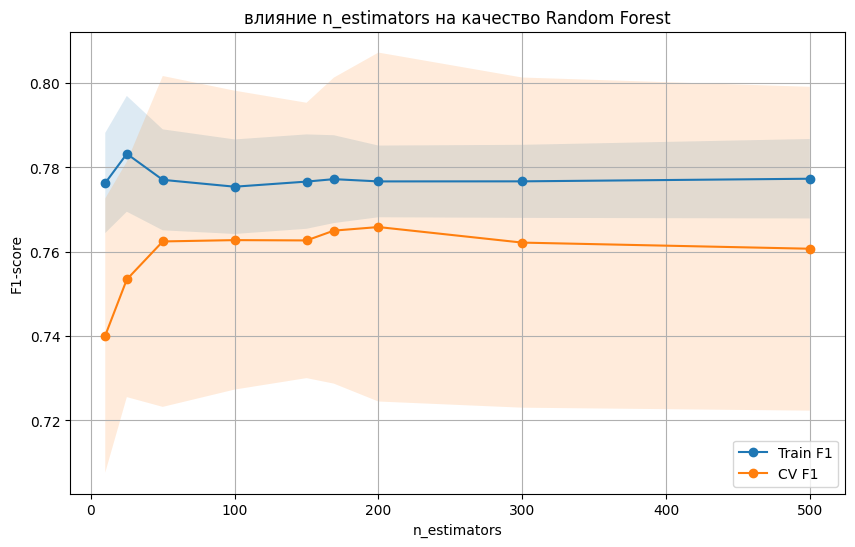

In [54]:
plt.figure(figsize=(10, 6))

plt.plot(n_estimators_range, train_mean,
         marker='o', label='Train F1')

plt.plot(n_estimators_range, cv_mean,
         marker='o', label='CV F1')

plt.fill_between(
    n_estimators_range,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

plt.fill_between(
    n_estimators_range,
    cv_mean - cv_std,
    cv_mean + cv_std,
    alpha=0.15
)

plt.xlabel('n_estimators')
plt.ylabel('F1-score')
plt.title('влияние n_estimators на качество Random Forest')
plt.legend()
plt.grid()
plt.show()

**глубина**

In [55]:
max_depth_range = [2, 3, 4, 5, 6, 8, 10, None]

In [56]:
train_scores, cv_scores = validation_curve(
    estimator=best_random_model,
    X=X_train,
    y=y_train,
    param_name='classifier__max_depth',
    param_range=max_depth_range,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

In [57]:
train_mean = train_scores.mean(axis=1)
cv_mean = cv_scores.mean(axis=1)

train_std = train_scores.std(axis=1)
cv_std = cv_scores.std(axis=1)

for i, depth in enumerate(max_depth_range):
    print(
        f"max_depth={depth}: "
        f"Train F1={train_mean[i]:.4f}, "
        f"CV F1={cv_mean[i]:.4f}, "
        f"Std CV={cv_std[i]:.4f}"
    )

max_depth=2: Train F1=0.7302, CV F1=0.7286, Std CV=0.0405
max_depth=3: Train F1=0.7594, CV F1=0.7509, Std CV=0.0496
max_depth=4: Train F1=0.7772, CV F1=0.7650, Std CV=0.0363
max_depth=5: Train F1=0.7943, CV F1=0.7442, Std CV=0.0424
max_depth=6: Train F1=0.8122, CV F1=0.7527, Std CV=0.0378
max_depth=8: Train F1=0.8383, CV F1=0.7309, Std CV=0.0411
max_depth=10: Train F1=0.8460, CV F1=0.7386, Std CV=0.0511
max_depth=None: Train F1=0.8468, CV F1=0.7382, Std CV=0.0373


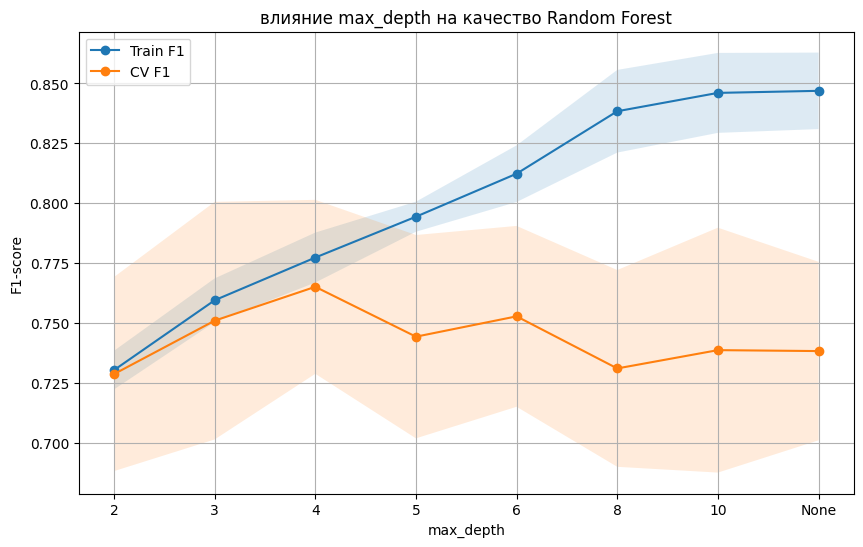

In [58]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(len(max_depth_range)),
    train_mean,
    marker='o',
    label='Train F1'
)

plt.plot(
    range(len(max_depth_range)),
    cv_mean,
    marker='o',
    label='CV F1'
)

plt.fill_between(
    range(len(max_depth_range)),
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

plt.fill_between(
    range(len(max_depth_range)),
    cv_mean - cv_std,
    cv_mean + cv_std,
    alpha=0.15
)

plt.xticks(
    range(len(max_depth_range)),
    [str(x) for x in max_depth_range]
)

plt.xlabel('max_depth')
plt.ylabel('F1-score')
plt.title('влияние max_depth на качество Random Forest')

plt.legend()
plt.grid()
plt.show()

**мин объектов для разделения узла**

In [59]:
min_samples_split_range = [2, 4, 6, 8, 10, 12, 15, 20]

In [60]:
train_scores, cv_scores = validation_curve(
    estimator=best_random_model,
    X=X_train,
    y=y_train,
    param_name='classifier__min_samples_split',
    param_range=min_samples_split_range,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

In [61]:
train_mean = train_scores.mean(axis=1)
cv_mean = cv_scores.mean(axis=1)

train_std = train_scores.std(axis=1)
cv_std = cv_scores.std(axis=1)

for i, value in enumerate(min_samples_split_range):
    print(
        f"min_samples_split={value}: "
        f"Train F1={train_mean[i]:.4f}, "
        f"CV F1={cv_mean[i]:.4f}, "
        f"Std CV={cv_std[i]:.4f}"
    )

min_samples_split=2: Train F1=0.7793, CV F1=0.7636, Std CV=0.0377
min_samples_split=4: Train F1=0.7793, CV F1=0.7636, Std CV=0.0377
min_samples_split=6: Train F1=0.7767, CV F1=0.7612, Std CV=0.0341
min_samples_split=8: Train F1=0.7759, CV F1=0.7636, Std CV=0.0377
min_samples_split=10: Train F1=0.7772, CV F1=0.7650, Std CV=0.0363
min_samples_split=12: Train F1=0.7766, CV F1=0.7625, Std CV=0.0370
min_samples_split=15: Train F1=0.7735, CV F1=0.7636, Std CV=0.0377
min_samples_split=20: Train F1=0.7741, CV F1=0.7621, Std CV=0.0379


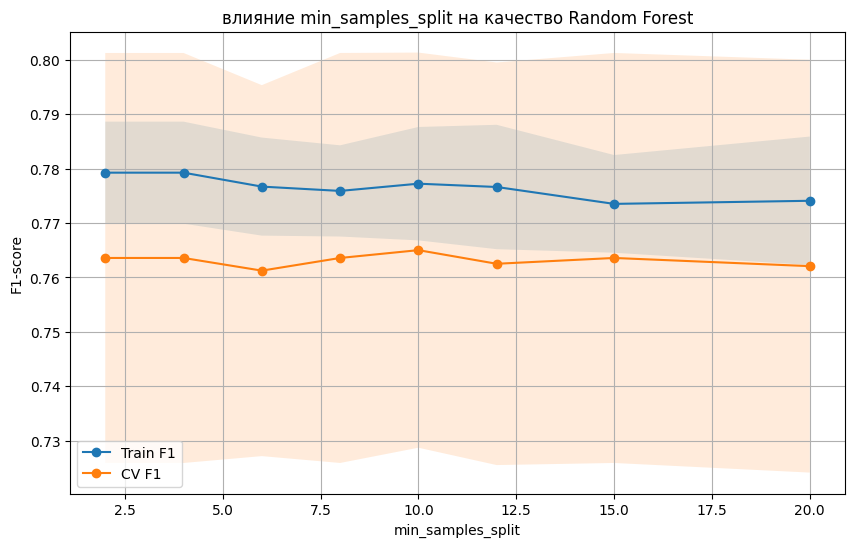

In [62]:
plt.figure(figsize=(10, 6))

plt.plot(min_samples_split_range, train_mean,
         marker='o', label='Train F1')

plt.plot(min_samples_split_range, cv_mean,
         marker='o', label='CV F1')

plt.fill_between(
    min_samples_split_range,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

plt.fill_between(
    min_samples_split_range,
    cv_mean - cv_std,
    cv_mean + cv_std,
    alpha=0.15
)

plt.xlabel('min_samples_split')
plt.ylabel('F1-score')
plt.title('влияние min_samples_split на качество Random Forest')
plt.legend()
plt.grid()
plt.show()

**мин объектов в листе**

In [63]:
min_samples_leaf_range = [1, 2, 3, 4, 5, 6, 8, 10]

In [64]:
train_scores, cv_scores = validation_curve(
    estimator=best_random_model,
    X=X_train,
    y=y_train,
    param_name='classifier__min_samples_leaf',
    param_range=min_samples_leaf_range,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

In [65]:
train_mean = train_scores.mean(axis=1)
cv_mean = cv_scores.mean(axis=1)

train_std = train_scores.std(axis=1)
cv_std = cv_scores.std(axis=1)

for i, value in enumerate(min_samples_leaf_range):
    print(
        f"min_samples_leaf={value}: "
        f"Train F1={train_mean[i]:.4f}, "
        f"CV F1={cv_mean[i]:.4f}, "
        f"Std CV={cv_std[i]:.4f}"
    )

min_samples_leaf=1: Train F1=0.7812, CV F1=0.7650, Std CV=0.0363
min_samples_leaf=2: Train F1=0.7772, CV F1=0.7650, Std CV=0.0363
min_samples_leaf=3: Train F1=0.7746, CV F1=0.7636, Std CV=0.0377
min_samples_leaf=4: Train F1=0.7745, CV F1=0.7652, Std CV=0.0403
min_samples_leaf=5: Train F1=0.7712, CV F1=0.7638, Std CV=0.0397
min_samples_leaf=6: Train F1=0.7709, CV F1=0.7598, Std CV=0.0332
min_samples_leaf=8: Train F1=0.7729, CV F1=0.7486, Std CV=0.0288
min_samples_leaf=10: Train F1=0.7675, CV F1=0.7485, Std CV=0.0336


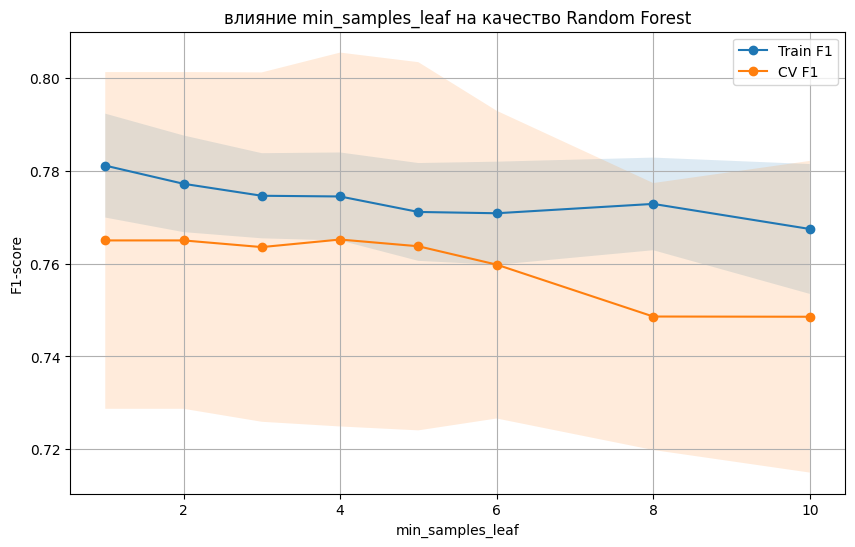

In [66]:
plt.figure(figsize=(10, 6))

plt.plot(min_samples_leaf_range, train_mean,
         marker='o', label='Train F1')

plt.plot(min_samples_leaf_range, cv_mean,
         marker='o', label='CV F1')

plt.fill_between(
    min_samples_leaf_range,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

plt.fill_between(
    min_samples_leaf_range,
    cv_mean - cv_std,
    cv_mean + cv_std,
    alpha=0.15
)

plt.xlabel('min_samples_leaf')
plt.ylabel('F1-score')
plt.title('влияние min_samples_leaf на качество Random Forest')
plt.legend()
plt.grid()
plt.show()

# Финальная модель

In [67]:
models = {
    'Baseline': baseline_pipeline,
    'Grid Search': grid_search.best_estimator_,
    'Random Search': random_search.best_estimator_
}

In [68]:
baseline_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler()),
                                                                  ('imputer',
                                                                   KNNImputer())]),
                                                  ['Age', 'SibSp', 'Parch',
                                                   'Fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Pclass', 'Sex', 'Embarked',
                                                   'Title'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

In [69]:
predictions = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test)

In [72]:
cv_scores = {
    'Baseline': cross_val_score(
        baseline_pipeline, X_train, y_train,
        cv=cv, scoring='f1', n_jobs=-1
    ).mean(),

    'Grid Search': grid_search.best_score_,

    'Random Search': random_search.best_score_
}

results = []

for name, y_pred in predictions.items():
    results.append({
        'Model': name,
        'CV F1-score': cv_scores[name],
        'Test F1-score': f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

           Model  CV F1-score  Test F1-score
0       Baseline       0.7364         0.7273
1    Grid Search       0.7581         0.7302
2  Random Search       0.7650         0.7402


#Анализ устойчивости

In [ ]:
stability_results = {
    'Baseline': [0.78899083, 0.69811321, 0.75925926,
                 0.71028037, 0.72549020],

    'Grid Search': [0.78181818, 0.70588235, 0.84615385,
                    0.71153846, 0.74509804],

    'Random Search': [0.78504673, 0.73267327, 0.82352941,
                      0.72380952, 0.76000000]
}

stability_df = pd.DataFrame(
    stability_results,
    index=[f'Fold {i}' for i in range(1, 6)]
)

print("F1-score на каждом проверочном фолде")
display(stability_df.round(4))

In [ ]:
summary = pd.DataFrame({
    'Mean F1': stability_df.mean(),
    'Std F1': stability_df.std(ddof=0),
    'Min F1': stability_df.min(),
    'Max F1': stability_df.max(),
    'Range': stability_df.max() - stability_df.min()
})

print("таблица устойчивости")
display(summary.round(4))